Dataset Loaded Successfully


,rownames,Gunnel,Time,Fromlow,Slope,Rw,Amphiso,Subst,Pool,Water,Cobble
0,1,0,786,190,10,0.1,0,3,0,0,0
1,2,0,794,182,10,0.0,0,3,0,0,0
2,3,0,798,178,20,0.0,0,1,0,0,0
3,4,0,800,176,70,0.3,0,1,0,1,0
4,5,0,804,172,40,0.3,0,1,0,1,0


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1592 entries, 0 to 1591
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  1592 non-null   int64  
 1   Gunnel    1592 non-null   int64  
 2   Time      1592 non-null   int64  
 3   Fromlow   1592 non-null   int64  
 4   Slope     1592 non-null   int64  
 5   Rw        1592 non-null   float64
 6   Amphiso   1592 non-null   int64  
 7   Subst     1592 non-null   int64  
 8   Pool      1592 non-null   int64  
 9   Water     1592 non-null   int64  
 10  Cobble    1592 non-null   int64  
dtypes: float64(1), int64(10)
memory usage: 136.9 KB
Numerical Variables:
['rownames', 'Gunnel', 'Time', 'Fromlow', 'Slope', 'Rw', 'Amphiso', 'Subst', 'Pool', 'Water', 'Cobble']
Categorical Variables:
['Water', 'Cobble', 'Pool', 'Gunnel']


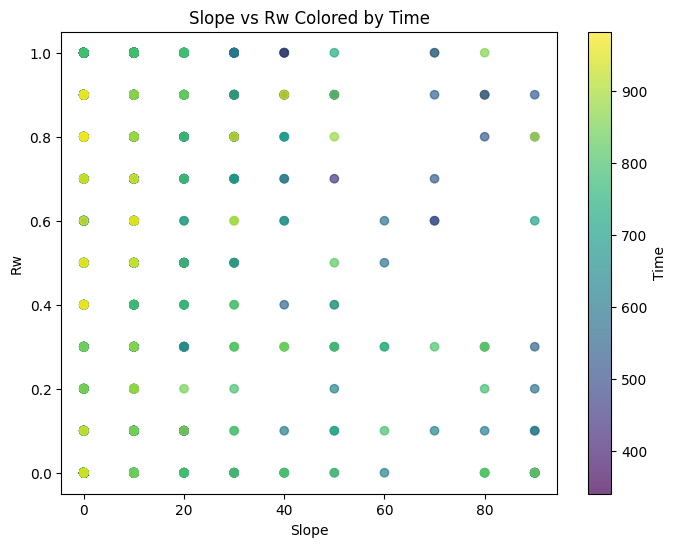

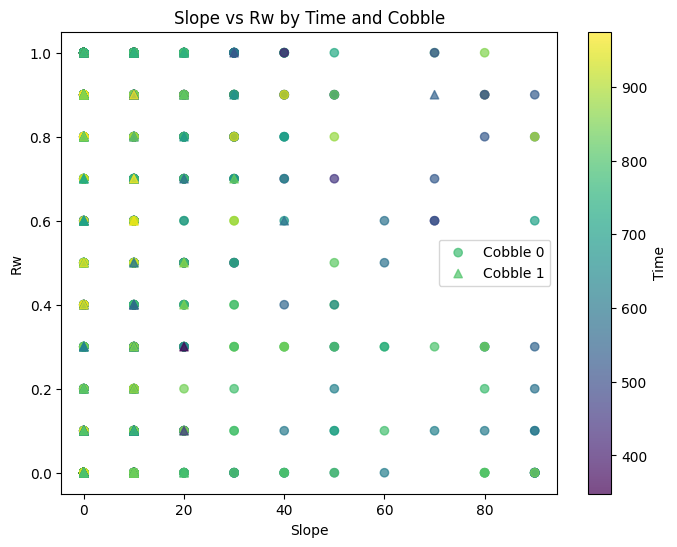

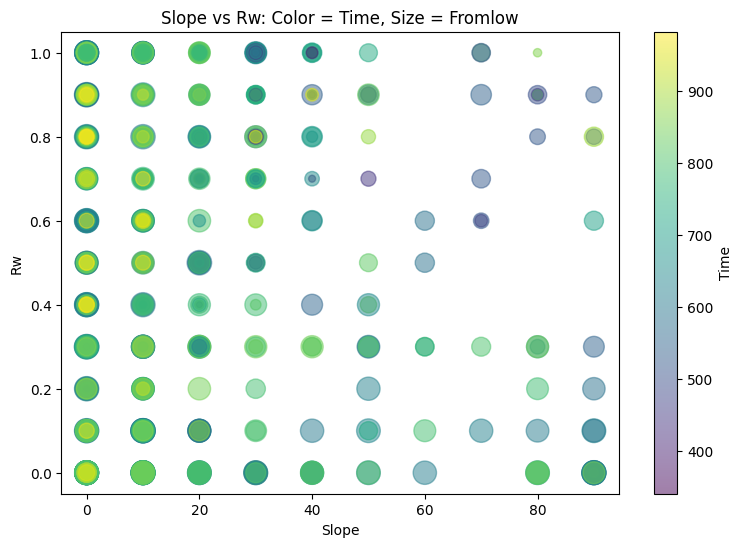

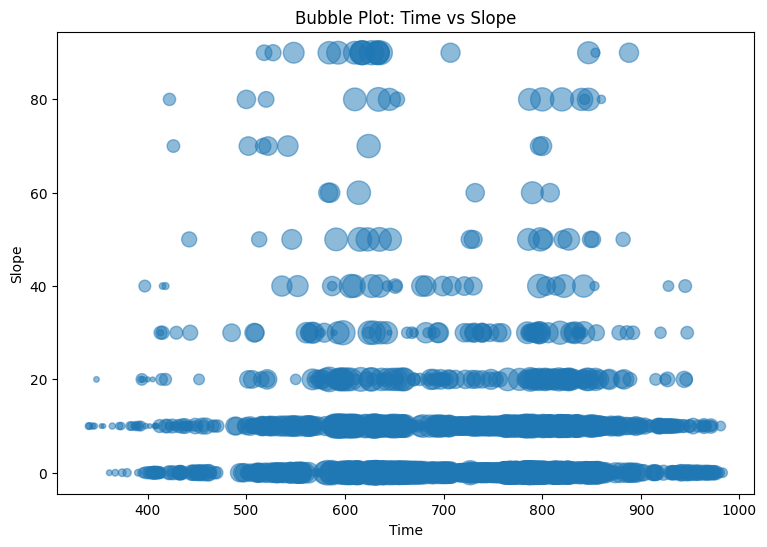

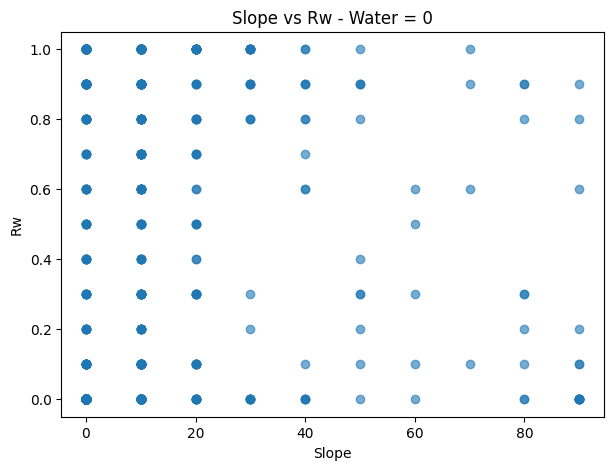

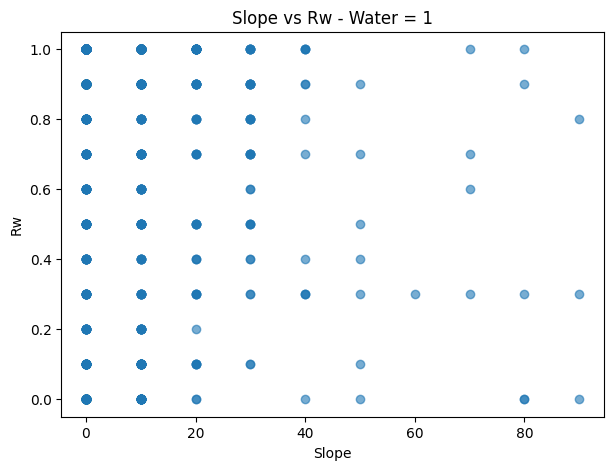

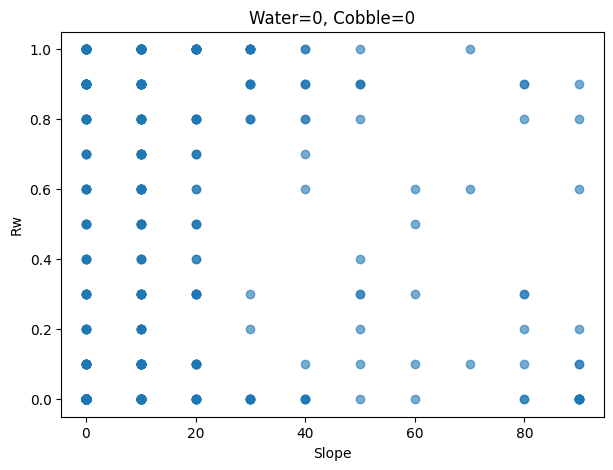

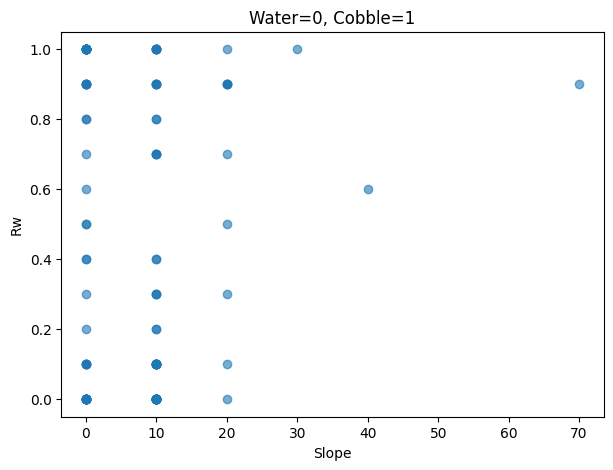

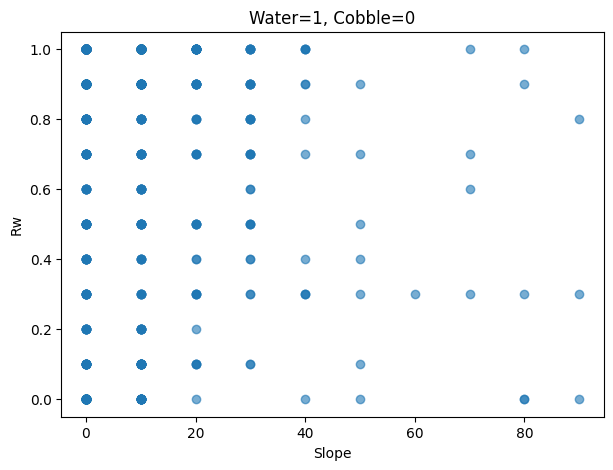

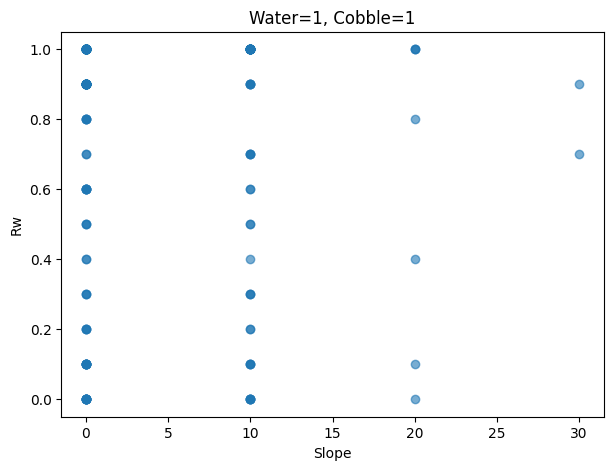

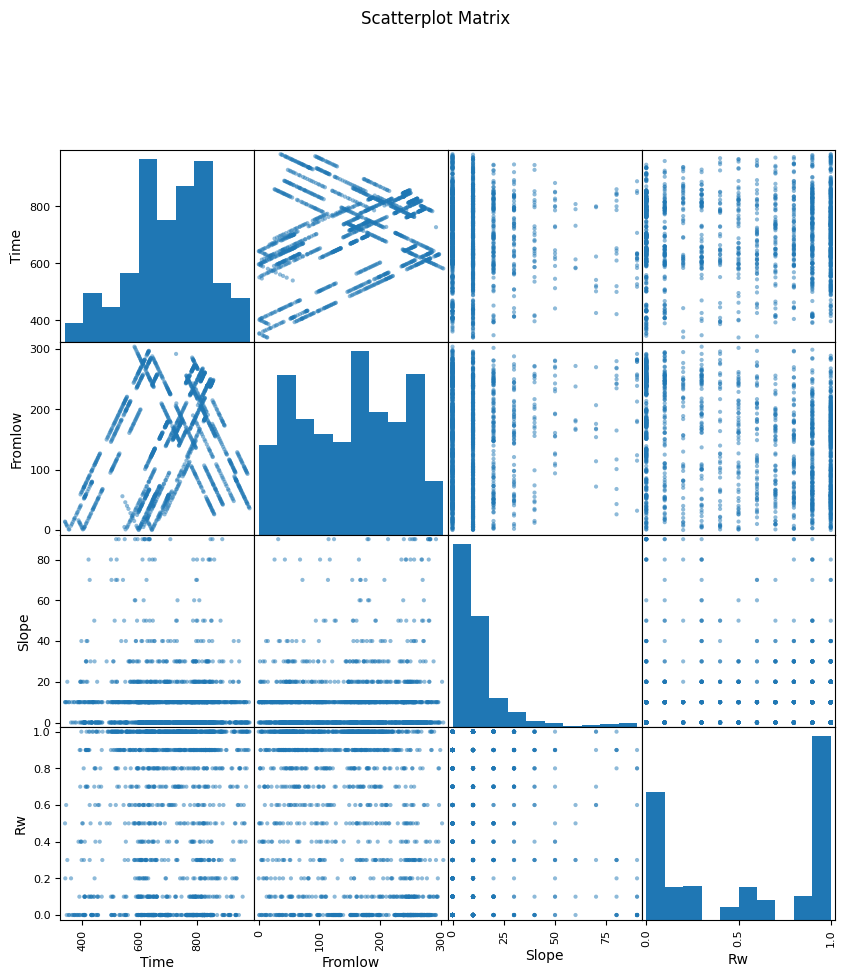

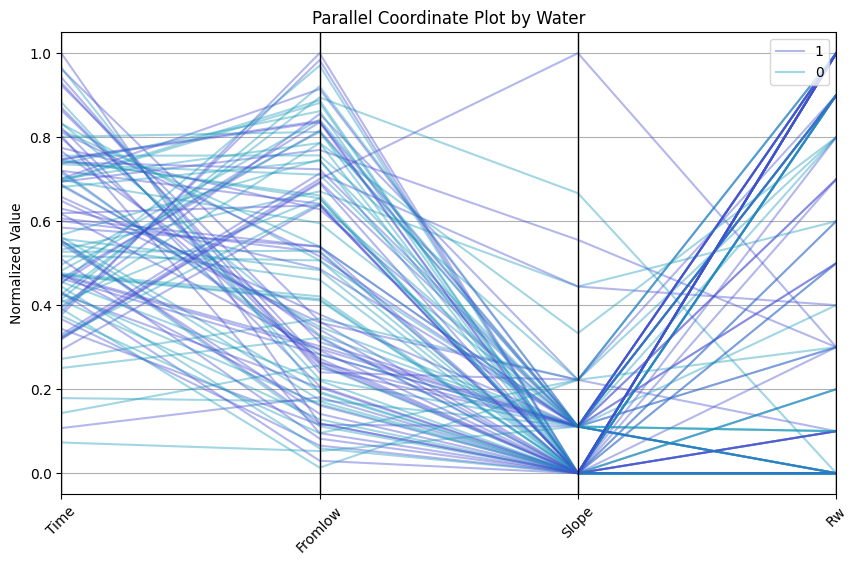

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from pandas.plotting import parallel_coordinates

# ASSESSMENT 5
# MULTIVARIATE ANALYSIS

# 1. Load Dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Gunnels.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

display(df.head())

print("Dataset Information:")
df.info()

print("Numerical Variables:")
print(
    df.select_dtypes(
        include=np.number
    ).columns.tolist()
)

# Convert selected coded variables into categories
df["Water"] = df["Water"].astype(str)
df["Cobble"] = df["Cobble"].astype(str)
df["Pool"] = df["Pool"].astype(str)
df["Gunnel"] = df["Gunnel"].astype(str)

print("Categorical Variables:")
print(["Water", "Cobble", "Pool", "Gunnel"])

# 2. Scatter Plot With Three Variables
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["Slope"],
    df["Rw"],
    c=df["Time"],
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(
    scatter,
    label="Time"
)

plt.title("Slope vs Rw Colored by Time")
plt.xlabel("Slope")
plt.ylabel("Rw")
plt.show()

# 3. Scatter Plot With Four Variables
shape_map = {
    "0": "o",
    "1": "^"
}

plt.figure(figsize=(8, 6))

for cobble_value in df["Cobble"].unique():

    subset = df[
        df["Cobble"] == cobble_value
    ]

    plt.scatter(
        subset["Slope"],
        subset["Rw"],
        c=subset["Time"],
        cmap="viridis",
        marker=shape_map.get(
            cobble_value,
            "o"
        ),
        label=f"Cobble {cobble_value}",
        alpha=0.7
    )

plt.colorbar(label="Time")

plt.title(
    "Slope vs Rw by Time and Cobble"
)

plt.xlabel("Slope")
plt.ylabel("Rw")
plt.legend()
plt.show()

# 4. Four Variables Using Color and Size
sizes = (
    df["Fromlow"]
    - df["Fromlow"].min()
    + 10
)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["Slope"],
    df["Rw"],
    c=df["Time"],
    s=sizes,
    cmap="viridis",
    alpha=0.5
)

plt.colorbar(
    scatter,
    label="Time"
)

plt.title(
    "Slope vs Rw: Color = Time, Size = Fromlow"
)

plt.xlabel("Slope")
plt.ylabel("Rw")
plt.show()

# 5. Bubble Plot
bubble_size = (
    df["Fromlow"]
    - df["Fromlow"].min()
    + 10
)

plt.figure(figsize=(9, 6))

plt.scatter(
    df["Time"],
    df["Slope"],
    s=bubble_size,
    alpha=0.5
)

plt.title(
    "Bubble Plot: Time vs Slope"
)

plt.xlabel("Time")
plt.ylabel("Slope")

plt.show()

# 6. Facet Wrap Equivalent
categories = sorted(
    df["Water"].unique()
)

for category in categories:

    subset = df[
        df["Water"] == category
    ]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        subset["Slope"],
        subset["Rw"],
        alpha=0.6
    )

    plt.title(
        f"Slope vs Rw - Water = {category}"
    )

    plt.xlabel("Slope")
    plt.ylabel("Rw")

    plt.show()

# 7. Facet Grid Equivalent
water_values = sorted(
    df["Water"].unique()
)

cobble_values = sorted(
    df["Cobble"].unique()
)

for water in water_values:

    for cobble in cobble_values:

        subset = df[
            (df["Water"] == water)
            &
            (df["Cobble"] == cobble)
        ]

        if len(subset) > 0:

            plt.figure(figsize=(7, 5))

            plt.scatter(
                subset["Slope"],
                subset["Rw"],
                alpha=0.6
            )

            plt.title(
                f"Water={water}, Cobble={cobble}"
            )

            plt.xlabel("Slope")
            plt.ylabel("Rw")

            plt.show()

# 8. Pairs Plot
pair_columns = [
    "Time",
    "Fromlow",
    "Slope",
    "Rw"
]

scatter_matrix(
    df[pair_columns],
    figsize=(10, 10),
    diagonal="hist"
)

plt.suptitle(
    "Scatterplot Matrix",
    y=1.02
)

plt.show()

# 9. Parallel Coordinate Plot
parallel_df = df[
    [
        "Time",
        "Fromlow",
        "Slope",
        "Rw",
        "Water"
    ]
].copy()

# Scale numerical features for readability
numeric_features = [
    "Time",
    "Fromlow",
    "Slope",
    "Rw"
]

for column in numeric_features:

    minimum = parallel_df[
        column
    ].min()

    maximum = parallel_df[
        column
    ].max()

    parallel_df[column] = (
        parallel_df[column] - minimum
    ) / (
        maximum - minimum
    )

parallel_sample = parallel_df.sample(
    n=min(100, len(parallel_df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

parallel_coordinates(
    parallel_sample,
    class_column="Water",
    alpha=0.4
)

plt.title(
    "Parallel Coordinate Plot by Water"
)

plt.ylabel("Normalized Value")

plt.xticks(rotation=45)

plt.show()